# ML walkthrough — check every step yourself

This notebook goes through Component 3's machine-learning part **one step at a
time, on the real data files**, so you can see what happens at each stage and
check the results by hand instead of trusting a printed number.

**How to use it:** click a cell and press **Shift + Enter** to run it, top to
bottom. (First time: VS Code asks for a kernel — pick the Python 3.13 one.)
Cells that print PASS contain a check: if something were wrong, that cell would stop
with an error.

| Part | What you check |
|---|---|
| A | The raw data: what it looks like, how messy it is |
| B | Cleaning: counted by hand, compared with the cleaning report |
| C | Leakage: vendor history really uses only earlier events |
| D | The train/test split by date |
| E | What the model sees, and the saved model |
| F | Accuracy, computed by hand and compared with the official numbers |
| G | One prediction explained, feature by feature |
| H | Your own "what if" predictions |
| I | The late-vendor model: confusion matrix and AUC by hand |

**Where you can run it:** in VS Code on the project folder, on any other
computer with Python 3.11+, or in **Google Colab** — the first cell below
detects Colab, downloads the project from GitHub and installs the libraries.

### 0 · Setup (run this first)

- **On your own laptop / in VS Code:** nothing to install; this cell only
  finds the project folder.
- **In Google Colab:** this cell downloads branch
  `event-planning-dynamic-resource-optimization/dinuja` from the public
  GitHub repo and installs the libraries, then **restarts the session once**
  (Colab shows "session crashed" — that is expected). After that, run this
  cell again and continue.

In [1]:
import os, sys, subprocess
REPO = "https://github.com/fernandoshamod/J26-IT-383.git"
BRANCH = "event-planning-dynamic-resource-optimization/dinuja"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    target = "/content/J26-IT-383"
    if not os.path.exists(target):
        subprocess.run(["git", "clone", "--depth", "1", "-b", BRANCH, REPO, target], check=True)
        # Same library versions the models were trained with, so the checks match exactly.
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{target}/requirements.txt",
                        "xgboost==3.4.1", "scikit-learn==1.9.1"], check=True)
        print("Installed. Restarting the session once — then run this cell again.")
        os.kill(os.getpid(), 9)
    os.chdir(target)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print("Project folder:", os.getcwd())

Project folder: C:\Users\ASUS\Desktop\SLIIT\4.1\reserch\research


In [2]:
# Libraries and project code.
import os, sys, json, math, platform
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scheduling_engine.history_generation import generate_history, ACTIVITY_PROFILES
from scheduling_engine.data_preparation import clean_activity_records, clean_arrival_records, canonical_activity
from scheduling_engine import duration_prediction as dp
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
import xgboost, sklearn
print("Working in:", os.getcwd())
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__}")
if xgboost.__version__ != "3.4.1":
    print("Note: the saved models were trained with xgboost 3.4.1; a different version can change "
          "the retraining check slightly. Install it with: pip install xgboost==3.4.1")

Working in: C:\Users\ASUS\Desktop\SLIIT\4.1\reserch\research
Python 3.13.3 | numpy 2.5.3 | pandas 3.0.6 | scikit-learn 1.9.1 | xgboost 3.4.1


## A · The raw data

These two CSV files are the *raw* historical records the models learn from.
They are synthetic (no public event-duration dataset exists — proposal §3.3.2),
produced by `scheduling_engine/history_generation.py` with seed 42, and made
deliberately messy, like a real export.

In [3]:
raw_act = pd.read_csv("data/historical/raw_activity_records.csv")
raw_arr = pd.read_csv("data/historical/raw_vendor_arrivals.csv")
print("activity rows:", len(raw_act), "| events:", raw_act.event_id.nunique(), "| vendor-arrival rows:", len(raw_arr))
raw_act.head(10)

activity rows: 8378 | events: 800 | vendor-arrival rows: 4000


,event_id,event_date,event_type,guest_count,venue_type,activity_name,planned_start_hour,planned_duration_minutes,crew_size,vendor_id,vendor_prior_jobs,actual_duration_minutes
0,E0000,2022-01-01,wedding,175.0,indoor,venue_setup,12,80,2,NaN,NaN,105
1,E0000,2022-01-01,wedding,175.0,indoor,decoration,13,60,2,florist_01,0.0,79
2,E0000,2022-01-01,wedding,175.0,indoor,sound_check,14,35,2,av_vendor_07,0.0,29
3,E0000,2022-01-01,wedding,175.0,indoor,food load in,15,40,2,caterer_08,0.0,56
4,E0000,2022-01-01,wedding,175.0,indoor,guest_arrival,16,35,2,NaN,NaN,37
5,E0000,2022-01-01,wedding,175.0,indoor,ceremony,16,30,2,NaN,NaN,33
6,E0000,2022-01-01,wedding,175.0,indoor,photos,17,45,2,photographer_04,0.0,59
7,E0000,2022-01-01,wedding,175.0,indoor,dinner_service,18,65,2,NaN,NaN,83
8,E0000,2022-01-01,wedding,175.0,indoor,band,19,80,2,band_dj_08,0.0,109
9,E0000,2022-01-01,wedding,175.0,indoor,load-out,20,65,2,NaN,NaN,58


**One event, all its activities** — read it like a real event's record: planned vs actual minutes.

In [4]:
raw_act[raw_act.event_id == "E0100"][["event_date", "event_type", "guest_count", "venue_type",
                                        "activity_name", "planned_duration_minutes", "actual_duration_minutes"]]

,event_date,event_type,guest_count,venue_type,activity_name,planned_duration_minutes,actual_duration_minutes
1048,2022-07-11,corporate,139.0,outdoor,venue_setup,100,95
1049,2022-07-11,corporate,139.0,outdoor,decor,60,64
1050,2022-07-11,corporate,139.0,outdoor,sound_check,30,23
1051,2022-07-11,corporate,139.0,outdoor,catering_load_in,45,38
1052,2022-07-11,corporate,139.0,outdoor,guest_arrival,25,31
1053,2022-07-11,corporate,139.0,outdoor,photos,40,61
1054,2022-07-11,corporate,139.0,outdoor,Dinner,60,49
1055,2022-07-11,corporate,139.0,outdoor,entertainment,100,82
1056,2022-07-11,corporate,139.0,outdoor,strike,55,61


**Messy names:** the same activity is written many ways. Here are all the spellings used for catering load-in.

In [5]:
names = raw_act.activity_name.value_counts()
print("distinct spellings in the raw file:", len(names))
names[[n for n in names.index if canonical_activity(n) == "catering_load_in"]]

distinct spellings in the raw file: 55


activity_name
catering_load_in    596
food load in         63
Catering Load-in     48
catering_loadin      47
Catering load in     46
Name: count, dtype: int64

**Impossible durations** — find them yourself: zero, negative, or more than 4× the plan (a typo).

In [6]:
bad = raw_act[(raw_act.actual_duration_minutes <= 0) |
              (raw_act.actual_duration_minutes > 4 * raw_act.planned_duration_minutes)]
print("impossible rows found by hand:", len(bad))
bad[["event_id", "activity_name", "planned_duration_minutes", "actual_duration_minutes"]].head(10)

impossible rows found by hand: 29


,event_id,activity_name,planned_duration_minutes,actual_duration_minutes
357,E0033,strike,55,490
520,E0049,dinner_service,60,620
827,E0078,speeches,20,-30
1021,E0097,ceremony,30,360
1103,E0105,guest_arrival,40,0
1275,E0121,Photos,45,0
1719,E0165,guest_arrival,30,-41
1796,E0172,Speeches & Toasts,20,-28
1797,E0172,entertainment,85,0
2431,E0233,guest_arrival,30,0


In [7]:
print("missing values per column (activities):")
raw_act.isna().sum()[lambda s: s > 0]

missing values per column (activities):


guest_count           287
vendor_id            4378
vendor_prior_jobs    4378
dtype: int64

## B · Cleaning

`clean_activity_records` applies three rules: map names through an alias
table, drop impossible durations, keep missing values as missing (XGBoost
handles them). Compare its report with what you counted by hand above.

In [8]:
act, act_report = clean_activity_records(raw_act)
arr, arr_report = clean_arrival_records(raw_arr)
print("\n".join(act_report.lines()))
# Checks: the cleaner removed exactly the rows you found by hand
assert act_report.dropped_impossible_duration == len(bad)
assert len(act) == len(raw_act) - len(bad)
assert act.activity_type.nunique() == len(ACTIVITY_PROFILES) == 11
print("\nPASS: cleaning matches the hand count; 11 clean activity types:", sorted(act.activity_type.unique()))

rows in:                         8378
activity names normalised:       2090
dropped (unknown activity name): 0
dropped (impossible duration):   29
missing guest_count (kept as NaN): 285
rows out:                        8349

PASS: cleaning matches the hand count; 11 clean activity types: ['catering_load_in', 'ceremony', 'decor', 'dinner_service', 'entertainment', 'guest_arrival', 'photos', 'sound_check', 'speeches', 'strike', 'venue_setup']


**Does the data contain the 'planning fallacy'?** Actual ÷ planned, averaged per
activity type. Speeches and photos overrun most; entertainment (a contracted
slot) barely overruns — exactly what the generator was told (see `ACTIVITY_PROFILES`).

In [9]:
ratio = (act.actual_duration_minutes / act.planned_duration_minutes).groupby(act.activity_type).mean().sort_values()
pd.DataFrame({"actual / planned (data)": ratio.round(2),
              "built-in overrun bias": [ACTIVITY_PROFILES[t]["bias"] for t in ratio.index]})

,actual / planned (data),built-in overrun bias
activity_type,,
entertainment,1.02,1.00
ceremony,1.07,1.05
sound_check,1.08,1.05
strike,1.12,1.05
venue_setup,1.16,1.10
dinner_service,1.17,1.10
catering_load_in,1.19,1.10
decor,1.22,1.15
guest_arrival,1.31,1.20


## C · Leakage check: vendor history uses only EARLIER events

The late-vendor model uses each vendor's past record. If that record included
the *current* or *future* jobs, the model would be cheating. Check one vendor:
recompute its "past average lateness" yourself from earlier rows only.

In [10]:
v = arr[arr.vendor_id == "caterer_05"].sort_values(["event_date", "event_id"]).reset_index(drop=True)
# By hand: average lateness of all EARLIER jobs (shift(1) = exclude the current row).
v["by_hand"] = v.lateness_minutes.shift(1).expanding().mean().round(2)
show = v[["event_date", "lateness_minutes", "vendor_prior_jobs", "vendor_prior_mean_lateness", "by_hand"]]
# Check: the stored feature equals the by-hand value on every row (first job: no history = missing)
assert (v.vendor_prior_jobs == range(len(v))).all()
assert np.allclose(v.vendor_prior_mean_lateness.iloc[1:], v.by_hand.iloc[1:], atol=0.01)
assert pd.isna(v.vendor_prior_mean_lateness.iloc[0])
print(f"PASS: caterer_05: {len(v)} jobs, history feature uses only earlier jobs")
show.head(8)

PASS: caterer_05: 93 jobs, history feature uses only earlier jobs


,event_date,lateness_minutes,vendor_prior_jobs,vendor_prior_mean_lateness,by_hand
0,2022-01-07,0,0,NaN,NaN
1,2022-01-21,0,1,0.0,0.0
2,2022-02-13,0,2,0.0,0.0
3,2022-02-26,0,3,0.0,0.0
4,2022-03-23,0,4,0.0,0.0
5,2022-03-26,0,5,0.0,0.0
6,2022-04-17,0,6,0.0,0.0
7,2022-04-28,29,7,0.0,0.0


## D · The split: train on the past, test on the future

Train = events from 2022–2024, test = events in 2025. The model never sees a
2025 event while learning, just as in real use it never sees the future.

In [11]:
data = dp.add_calendar_features(act)
train, test = dp.chronological_split(data)
print("train:", train.event_date.min(), "→", train.event_date.max(), "|", train.event_id.nunique(), "events,", len(train), "rows")
print("test :", test.event_date.min(), "→", test.event_date.max(), "|", test.event_id.nunique(), "events,", len(test), "rows")
# Check: no date overlap and no event in both
assert train.event_date.max() < test.event_date.min()
assert not set(train.event_id) & set(test.event_id)
print("PASS: no overlap between train and test")

train: 2022-01-01 → 2024-12-29 | 594 events, 6182 rows
test : 2025-01-02 → 2025-12-28 | 206 events, 2167 rows
PASS: no overlap between train and test


## E · What the model sees, and the saved model

The model only gets these columns — all known **when planning**, never the
actual duration or the day's real weather. This is the exact table fed to XGBoost.

In [12]:
model = dp.TrainedModel.load(dp.Path("models"), "duration")
print("features:", model.features)
print("chosen settings:", model.best_params, "| trees:", model.n_trees, "| cross-validation MAE:", round(model.cv_score, 2))
model.frame(test).head(5)

features: ['activity_type', 'event_type', 'venue_type', 'planned_duration_minutes', 'guest_count', 'crew_size', 'is_rainy_month', 'is_weekend', 'planned_start_hour', 'vendor_prior_jobs']
chosen settings: {'max_depth': 5, 'learning_rate': 0.05, 'min_child_weight': 5} | trees: 275 | cross-validation MAE: 6.32


,activity_type,event_type,venue_type,planned_duration_minutes,guest_count,crew_size,is_rainy_month,is_weekend,planned_start_hour,vendor_prior_jobs
0,venue_setup,corporate,indoor,105.0,119.0,2.0,0.0,0.0,12.0,NaN
1,decor,corporate,indoor,65.0,119.0,2.0,0.0,0.0,14.0,74.0
2,sound_check,corporate,indoor,25.0,119.0,2.0,0.0,0.0,15.0,65.0
3,catering_load_in,corporate,indoor,45.0,119.0,2.0,0.0,0.0,16.0,73.0
4,guest_arrival,corporate,indoor,30.0,119.0,2.0,0.0,0.0,16.0,NaN


**Optional — retrain it yourself.** This re-fits the model from scratch on the
training years with the chosen settings, then checks it predicts the same as
the saved file. (The full grid search with cross-validation is in
`examples/train_prediction_models.py`; it takes ~30 s.)

In [13]:
est = dp._new_estimator("regression", model.best_params, model.n_trees, early_stopping=False)
est.fit(model.frame(train), train[dp.DURATION_TARGET])
mine = np.clip(est.predict(model.frame(test)), 0, None)
saved = model.predict(test)
print("largest difference vs saved model:", round(float(np.abs(mine - saved).max()), 4), "minutes")
assert np.abs(mine - saved).max() < 0.01
print("PASS: retraining reproduces the saved model")

largest difference vs saved model: 0.0 minutes
PASS: retraining reproduces the saved model


## F · Accuracy, by hand

Predict every 2025 activity, then compute the mean absolute error (MAE) with
plain arithmetic — no library — for the model and for "trust the planner".

In [14]:
test = test.assign(predicted=model.predict(test))
rows = test[["activity_type", "guest_count", "venue_type", "planned_duration_minutes",
             "actual_duration_minutes", "predicted"]].copy()
rows["model error"] = (rows.predicted - rows.actual_duration_minutes).abs()
rows["planner error"] = (rows.planned_duration_minutes - rows.actual_duration_minutes).abs()
rows.head(10).round(1)

,activity_type,guest_count,venue_type,planned_duration_minutes,actual_duration_minutes,predicted,model error,planner error
0,venue_setup,119.0,indoor,105,102,99.900002,2.1,3
1,decor,119.0,indoor,65,57,66.900002,9.9,8
2,sound_check,119.0,indoor,25,27,31.100000,4.1,2
3,catering_load_in,119.0,indoor,45,52,48.000000,4.0,7
4,guest_arrival,119.0,indoor,30,40,33.099998,6.9,10
5,photos,119.0,indoor,40,53,55.099998,2.1,13
6,dinner_service,119.0,indoor,55,64,60.400002,3.6,9
7,entertainment,119.0,indoor,95,99,87.099998,11.9,4
8,strike,119.0,indoor,60,70,59.599998,10.4,10
9,venue_setup,376.0,indoor,110,115,107.000000,8.0,5


In [15]:
n = len(test)
mae_model = sum(abs(p - a) for p, a in zip(test.predicted, test.actual_duration_minutes)) / n
mae_planner = sum(abs(p - a) for p, a in zip(test.planned_duration_minutes, test.actual_duration_minutes)) / n
official = json.load(open("results/ml/metrics.json"))["duration"]["test"]
print(f"by hand: model MAE {mae_model:.2f} min | planner MAE {mae_planner:.2f} min | "
      f"{100 * (1 - mae_model / mae_planner):.1f}% less error")
print(f"official: model {official['XGBoost']['MAE']:.2f} | planner {official['B0 planner estimate (today' + chr(39) + 's practice)']['MAE']:.2f}")
# Check: the by-hand numbers equal the official results
assert abs(mae_model - official["XGBoost"]["MAE"]) < 0.01
print("PASS: by-hand MAE matches results/ml/metrics.json")

by hand: model MAE 6.41 min | planner MAE 11.23 min | 42.9% less error
official: model 6.41 | planner 11.23
PASS: by-hand MAE matches results/ml/metrics.json


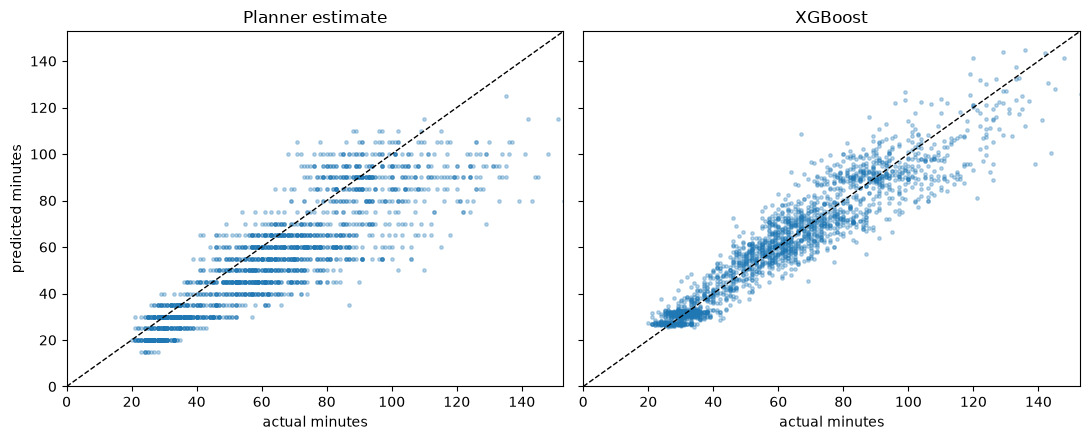

Points on the dashed line = perfect. The planner's points sit BELOW it (underestimates); the model's hug it.


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
lim = [0, float(test.actual_duration_minutes.quantile(0.995)) * 1.05]
for a, col, title in [(ax[0], "planned_duration_minutes", "Planner estimate"), (ax[1], "predicted", "XGBoost")]:
    a.scatter(test.actual_duration_minutes, test[col], s=6, alpha=0.3)
    a.plot(lim, lim, "k--", linewidth=1); a.set_xlim(lim); a.set_ylim(lim)
    a.set_title(title); a.set_xlabel("actual minutes")
ax[0].set_ylabel("predicted minutes"); plt.tight_layout(); plt.show()
print("Points on the dashed line = perfect. The planner's points sit BELOW it (underestimates); the model's hug it.")

**Noise ceiling.** The generator knows the hidden "true" expected duration for
each row (the *oracle*). No model can beat it — it's the best possible score.
The CSV doesn't contain it, so regenerate the data in memory (same seed) and
check it's identical to the CSV first.

In [17]:
gen_act, _ = generate_history(n_events=800, seed=42)
# Round-trip the regenerated data through CSV, then compare the VALUES with the file
# (comparing values, not text, works across pandas versions).
import io
regen = pd.read_csv(io.StringIO(gen_act.drop(columns=["oracle_duration_minutes"]).to_csv(index=False)))
pd.testing.assert_frame_equal(regen, raw_act)
print("PASS: regenerating with seed 42 reproduces the CSV exactly")
oracle = clean_activity_records(gen_act)[0]
o_test = dp.chronological_split(dp.add_calendar_features(oracle))[1]
mae_oracle = (o_test.oracle_duration_minutes - o_test.actual_duration_minutes).abs().mean()
print(f"oracle MAE {mae_oracle:.2f} | model {mae_model:.2f} | planner {mae_planner:.2f}")
print(f"model closes {100 * (mae_planner - mae_model) / (mae_planner - mae_oracle):.0f}% of the gap between planner and best possible")

PASS: regenerating with seed 42 reproduces the CSV exactly
oracle MAE 5.94 | model 6.41 | planner 11.23
model closes 91% of the gap between planner and best possible


## G · One prediction, explained feature by feature

SHAP splits a prediction into contributions: start from the average
prediction ("bias") and add each feature's push. The parts must add up to the
prediction exactly — check it.

In [18]:
row = test[(test.activity_type == "dinner_service")].head(1)
contrib = model.contributions(row).iloc[0]
pred = float(model.predict(row)[0])
print(f"{row.activity_type.iloc[0]}, {int(row.guest_count.iloc[0])} guests, {row.venue_type.iloc[0]}: "
      f"planned {int(row.planned_duration_minutes.iloc[0])}, actual {int(row.actual_duration_minutes.iloc[0])}, predicted {pred:.1f}")
table = contrib.drop("bias").sort_values(key=abs, ascending=False).round(2)
print(f"\nstart from the average prediction: {contrib['bias']:.2f} min")
print(table.to_string())
print(f"\nbias + all contributions = {contrib.sum():.2f}  (prediction {pred:.2f})")
assert abs(contrib.sum() - pred) < 0.01
print("PASS: the explanation adds up to the prediction")

dinner_service, 119 guests, indoor: planned 55, actual 64, predicted 60.4



start from the average prediction: 60.05 min
guest_count                -6.09
activity_type               5.29
planned_duration_minutes    1.73
planned_start_hour          0.50
venue_type                 -0.43
is_rainy_month             -0.34
vendor_prior_jobs          -0.12
crew_size                  -0.11
is_weekend                 -0.05
event_type                 -0.05

bias + all contributions = 60.38  (prediction 60.38)
PASS: the explanation adds up to the prediction


## H · Your own "what if"

Change the inputs and see how the prediction moves. Try more guests, an
outdoor venue, a rainy month (May, Jun, Sep, Oct, Nov), a bigger crew, or a
new vendor (few past jobs).

In [19]:
def predict_one(activity_type, planned, guests=150, venue="indoor", date="2026-03-14",
                event_type="wedding", crew=2, start_hour=12, vendor_jobs=None):
    df = dp.add_calendar_features(pd.DataFrame([dict(
        activity_type=activity_type, event_type=event_type, venue_type=venue,
        planned_duration_minutes=planned, guest_count=guests, crew_size=crew,
        event_date=date, planned_start_hour=start_hour, vendor_prior_jobs=vendor_jobs)]))
    return float(model.predict(df)[0])

print("dinner_service, planned 60:")
for guests in (100, 150, 250, 400):
    print(f"   {guests:>3} guests → {predict_one('dinner_service', 60, guests):.0f} min")
print("venue_setup, planned 90, 200 guests:")
for venue, date in [("indoor", "2026-03-14"), ("outdoor", "2026-03-14"), ("outdoor", "2026-10-24")]:
    print(f"   {venue:<7} {date} → {predict_one('venue_setup', 90, 200, venue, date):.0f} min")
print("photos, planned 45, 200 guests:")
for jobs in (2, 40):
    print(f"   photographer with {jobs:>2} past jobs → {predict_one('photos', 45, 200, vendor_jobs=jobs):.0f} min")

dinner_service, planned 60:
   100 guests → 57 min
   150 guests → 66 min
   250 guests → 78 min
   400 guests → 96 min
venue_setup, planned 90, 200 guests:
   indoor  2026-03-14 → 102 min
   outdoor 2026-03-14 → 104 min
   outdoor 2026-10-24 → 113 min
photos, planned 45, 200 guests:
   photographer with  2 past jobs → 67 min
   photographer with 40 past jobs → 59 min


## I · The late-vendor model, checked by hand

It gives a probability that a vendor arrives more than 10 minutes late (the
twin's tolerance). At a 50% threshold, count the four outcomes yourself.

In [20]:
late = dp.TrainedModel.load(dp.Path("models"), "lateness")
a_data = dp.add_calendar_features(arr)
a_train, a_test = dp.chronological_split(a_data)
p = late.predict(a_test)
y = a_test[dp.LATENESS_TARGET].to_numpy()
flag = p >= 0.5
tp = int(((flag == 1) & (y == 1)).sum()); fp = int(((flag == 1) & (y == 0)).sum())
fn = int(((flag == 0) & (y == 1)).sum()); tn = int(((flag == 0) & (y == 0)).sum())
print(f"2025 bookings: {len(y)} | actually late: {int(y.sum())} ({100 * y.mean():.0f}%)")
print(f"flagged & late (TP) {tp} | flagged but on time (FP) {fp} | missed late (FN) {fn} | correctly not flagged (TN) {tn}")
print(f"precision {tp / (tp + fp):.2f} (when it flags, how often it's right) | recall {tp / (tp + fn):.2f} (share of late vendors caught)")

2025 bookings: 1030 | actually late: 281 (27%)
flagged & late (TP) 56 | flagged but on time (FP) 32 | missed late (FN) 225 | correctly not flagged (TN) 717
precision 0.64 (when it flags, how often it's right) | recall 0.20 (share of late vendors caught)


**Choosing the threshold.** A warning only means "call the vendor the day
before", which is cheap, while a missed late vendor can start a cascade. So
catching more late vendors (recall) matters more than every warning being
right (precision). Compare thresholds:

In [21]:
rows = []
for th in (0.5, 0.4, 0.3, 0.2):
    f = p >= th
    tp_, fp_, fn_ = int(((f) & (y == 1)).sum()), int(((f) & (y == 0)).sum()), int(((~f) & (y == 1)).sum())
    rows.append(dict(threshold=th, flagged=int(f.sum()), precision=round(tp_ / (tp_ + fp_), 2), recall=round(tp_ / (tp_ + fn_), 2)))
print(f"base rate: {100 * y.mean():.0f}% of bookings are late — any precision above that beats guessing")
pd.DataFrame(rows)

base rate: 27% of bookings are late — any precision above that beats guessing


,threshold,flagged,precision,recall
0,0.5,88,0.64,0.20
1,0.4,200,0.54,0.38
2,0.3,299,0.50,0.53
3,0.2,464,0.45,0.74


In [22]:
# AUC by hand: pick one late and one on-time booking at random — how often does
# the late one get the higher probability? That fraction IS the ROC-AUC.
late_p, ontime_p = p[y == 1], p[y == 0]
wins = sum((lp > op) + 0.5 * (lp == op) for lp in late_p for op in ontime_p)
auc_by_hand = wins / (len(late_p) * len(ontime_p))
official_auc = json.load(open("results/ml/metrics.json"))["lateness"]["test"]["XGBoost"]["ROC_AUC"]
print(f"AUC by hand {auc_by_hand:.3f} | official {official_auc:.3f} | 0.5 would be a coin flip")
assert abs(auc_by_hand - official_auc) < 0.001
print("PASS: by-hand AUC matches the official result")

AUC by hand 0.762 | official 0.762 | 0.5 would be a coin flip
PASS: by-hand AUC matches the official result


## Summary

If every check printed PASS without an error, you have checked yourself that:

1. the raw data is as messy as described, and cleaning removed exactly the bad rows;
2. vendor history uses only earlier events (no leakage);
3. train and test don't overlap in time or events;
4. retraining reproduces the saved model;
5. the MAE (6.41 vs 11.23) and AUC (0.762) are correct when computed by hand;
6. each explanation adds up to its prediction;
7. the data regenerates identically from seed 42.

To rerun everything including the hyperparameter search, use
`python -m examples.train_prediction_models`.